In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

os.makedirs('outputs', exist_ok=True)

np.random.seed(42)
tf.random.set_seed(42)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 100

print(f"TensorFlow Version: {tf.__version__}")
print(f"OpenCV Version: {cv2.__version__}")

TensorFlow Version: 2.21.0
OpenCV Version: 5.0.0


In [2]:
(X_train_full, y_train_full), (X_test_full, y_test_full) = tf.keras.datasets.mnist.load_data()

print(f"Original Train Set: {X_train_full.shape}, Labels: {y_train_full.shape}")
print(f"Original Test Set:  {X_test_full.shape}, Labels: {y_test_full.shape}")


def extract_balanced_subset(X, y, samples_per_class=1000):
    selected_indices = []
    for digit in range(10):
        digit_indices = np.where(y == digit)[0]
        chosen = np.random.choice(digit_indices, samples_per_class, replace=False)
        selected_indices.extend(chosen)
    np.random.shuffle(selected_indices)
    return X[selected_indices], y[selected_indices]


X_train_sub, y_train_sub = extract_balanced_subset(X_train_full, y_train_full, samples_per_class=600)
X_test_sub, y_test_sub = extract_balanced_subset(X_test_full, y_test_full, samples_per_class=200)

print(f"Subset Training Shape: {X_train_sub.shape}, Labels: {y_train_sub.shape}")
print(f"Subset Testing Shape:  {X_test_sub.shape}, Labels: {y_test_sub.shape}")

Original Train Set: (60000, 28, 28), Labels: (60000,)
Original Test Set:  (10000, 28, 28), Labels: (10000,)
Subset Training Shape: (6000, 28, 28), Labels: (6000,)
Subset Testing Shape:  (2000, 28, 28), Labels: (2000,)


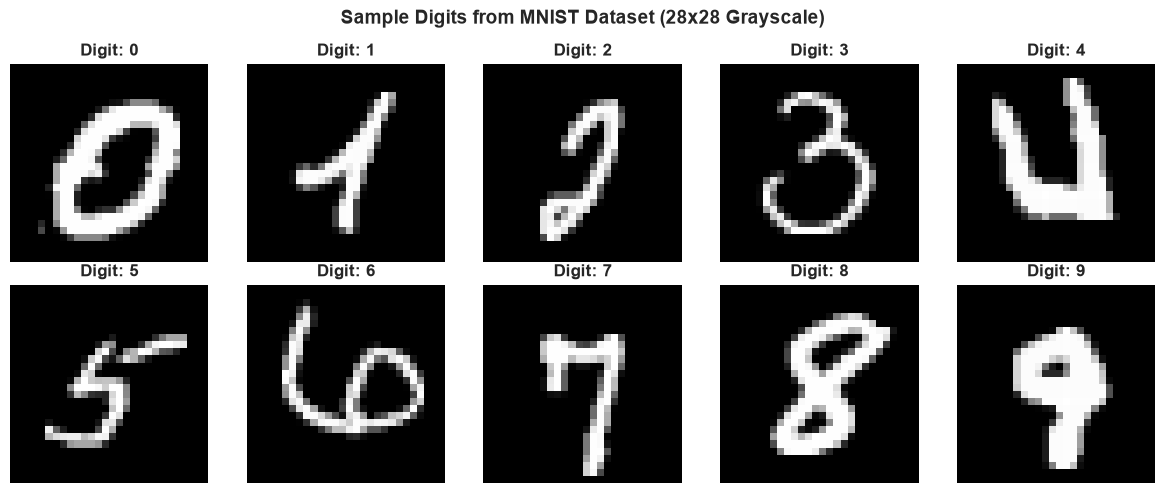

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for digit in range(10):
    row, col = divmod(digit, 5)
    sample_idx = np.where(y_train_sub == digit)[0][0]
    axes[row, col].imshow(X_train_sub[sample_idx], cmap='gray')
    axes[row, col].set_title(f"Digit: {digit}", fontsize=12, fontweight='bold')
    axes[row, col].axis('off')

plt.suptitle("Sample Digits from MNIST Dataset (28x28 Grayscale)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/raw_digits_sample.png', dpi=200, bbox_inches='tight')
plt.show()

In [4]:
def augment_opencv(image):
    img = image.copy().astype(np.uint8)
    h, w = img.shape[:2]

    angle = np.random.uniform(-15, 15)
    rot_mat = cv2.getRotationMatrix2D((w / 2, h / 2), angle, scale=1.0)
    img = cv2.warpAffine(img, rot_mat, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=0)

    dx = np.random.randint(-3, 4)
    dy = np.random.randint(-3, 4)
    trans_mat = np.float32([[1, 0, dx], [0, 1, dy]])
    img = cv2.warpAffine(img, trans_mat, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=0)

    if np.random.rand() > 0.5:
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
        if np.random.rand() > 0.5:
            img = cv2.dilate(img, kernel, iterations=1)
        else:
            img = cv2.erode(img, kernel, iterations=1)

    if np.random.rand() > 0.7:
        img = cv2.GaussianBlur(img, (3, 3), sigmaX=0.5)

    return img

In [5]:
tf_augmentation_layer = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.08, fill_mode='constant', fill_value=0.0),
    tf.keras.layers.RandomTranslation(0.1, 0.1, fill_mode='constant', fill_value=0.0),
    tf.keras.layers.RandomZoom(0.08, fill_mode='constant', fill_value=0.0),
])


def augment_tensorflow(image):
    img_tensor = tf.convert_to_tensor(image, dtype=tf.float32) / 255.0
    img_tensor = tf.reshape(img_tensor, [1, 28, 28, 1])

    augmented_tensor = tf_augmentation_layer(img_tensor, training=True)

    noise = tf.random.normal(shape=tf.shape(augmented_tensor), mean=0.0, stddev=0.04)
    augmented_tensor = tf.clip_by_value(augmented_tensor + noise, 0.0, 1.0)

    result = tf.squeeze(augmented_tensor * 255.0).numpy().astype(np.uint8)
    return result

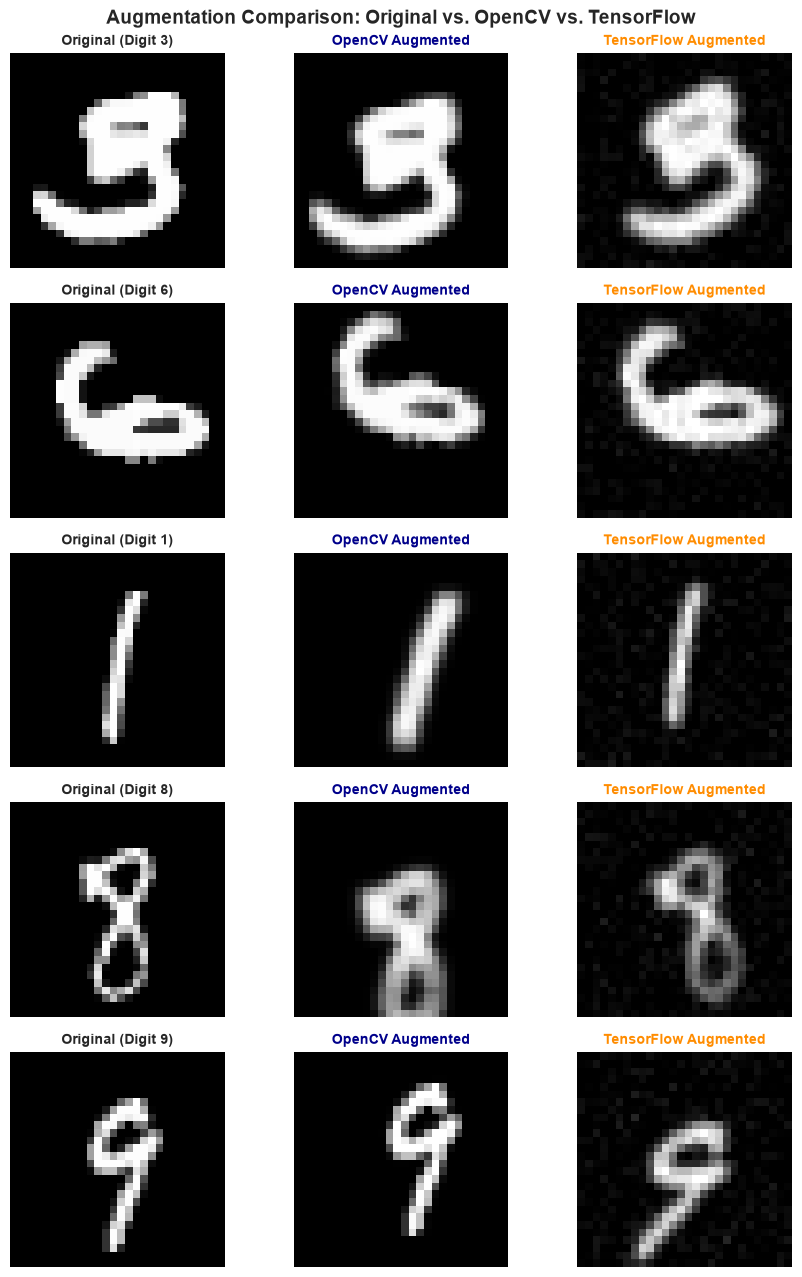

In [6]:
fig, axes = plt.subplots(5, 3, figsize=(9, 13))
sample_indices = np.random.choice(len(X_train_sub), 5, replace=False)

for i, idx in enumerate(sample_indices):
    orig_img = X_train_sub[idx]
    cv_img = augment_opencv(orig_img)
    tf_img = augment_tensorflow(orig_img)
    label = y_train_sub[idx]

    axes[i, 0].imshow(orig_img, cmap='gray')
    axes[i, 0].set_title(f"Original (Digit {label})", fontsize=10, fontweight='bold')
    axes[i, 0].axis('off')

    axes[i, 1].imshow(cv_img, cmap='gray')
    axes[i, 1].set_title("OpenCV Augmented", fontsize=10, color='darkblue', fontweight='bold')
    axes[i, 1].axis('off')

    axes[i, 2].imshow(tf_img, cmap='gray')
    axes[i, 2].set_title("TensorFlow Augmented", fontsize=10, color='darkorange', fontweight='bold')
    axes[i, 2].axis('off')

plt.suptitle("Augmentation Comparison: Original vs. OpenCV vs. TensorFlow", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/augmentation_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

In [7]:
print("Generating augmented training dataset...")
start_time = time.time()

X_train_cv = np.array([augment_opencv(img) for img in X_train_sub])
X_train_tf = np.array([augment_tensorflow(img) for img in X_train_sub])

X_train_combined = np.vstack([X_train_sub, X_train_cv, X_train_tf])
y_train_combined = np.concatenate([y_train_sub, y_train_sub, y_train_sub])

X_train_flat = X_train_combined.reshape(len(X_train_combined), -1).astype(np.float32)
X_test_flat = X_test_sub.reshape(len(X_test_sub), -1).astype(np.float32)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_flat)
X_test_scaled = scaler.transform(X_test_flat)

elapsed = time.time() - start_time
print(f"Augmentation & Preprocessing complete in {elapsed:.2f} seconds!")
print(f"Final Training Data Shape: {X_train_scaled.shape}, Labels: {y_train_combined.shape}")
print(f"Final Test Data Shape:     {X_test_scaled.shape}, Labels: {y_test_sub.shape}")

Generating augmented training dataset...


Augmentation & Preprocessing complete in 25.34 seconds!
Final Training Data Shape: (18000, 784), Labels: (18000,)
Final Test Data Shape:     (2000, 784), Labels: (2000,)


In [8]:
kernels = {
    "Linear": SVC(kernel='linear', C=1.0, random_state=42),
    "RBF (Gaussian)": SVC(kernel='rbf', C=5.0, gamma='scale', random_state=42),
    "Polynomial (d=3)": SVC(kernel='poly', degree=3, C=1.0, coef0=1.0, random_state=42)
}

results = {}

for name, model in kernels.items():
    print("=" * 50)
    print(f"Training SVM with {name} Kernel...")

    t0 = time.time()
    model.fit(X_train_scaled, y_train_combined)
    train_time = time.time() - t0

    t0 = time.time()
    y_pred = model.predict(X_test_scaled)
    infer_time = time.time() - t0

    acc = accuracy_score(y_test_sub, y_pred)
    cm = confusion_matrix(y_test_sub, y_pred)
    report = classification_report(y_test_sub, y_pred, output_dict=True)

    latency_per_sample_ms = (infer_time / len(X_test_scaled)) * 1000

    results[name] = {
        "model": model,
        "predictions": y_pred,
        "train_time": train_time,
        "infer_time": infer_time,
        "latency_ms": latency_per_sample_ms,
        "accuracy": acc,
        "macro_f1": report['macro avg']['f1-score'],
        "confusion_matrix": cm
    }

    print(f"[{name}] Training Time: {train_time:.2f}s | Test Accuracy: {acc*100:.2f}% | Latency: {latency_per_sample_ms:.3f} ms/sample")

Training SVM with Linear Kernel...


[Linear] Training Time: 131.43s | Test Accuracy: 81.15% | Latency: 1.121 ms/sample
Training SVM with RBF (Gaussian) Kernel...


[RBF (Gaussian)] Training Time: 43.19s | Test Accuracy: 96.45% | Latency: 2.527 ms/sample
Training SVM with Polynomial (d=3) Kernel...


[Polynomial (d=3)] Training Time: 22.99s | Test Accuracy: 96.15% | Latency: 1.072 ms/sample



--- 3-KERNEL COMPARISON SUMMARY TABLE ---
          Kernel Accuracy (%) Macro F1-Score Train Time (s) Inference Time (s) Latency (ms/sample)
          Linear       81.15%         0.8096         131.43               2.24               1.121
  RBF (Gaussian)       96.45%         0.9645          43.19               5.05               2.527
Polynomial (d=3)       96.15%         0.9614          22.99               2.14               1.072


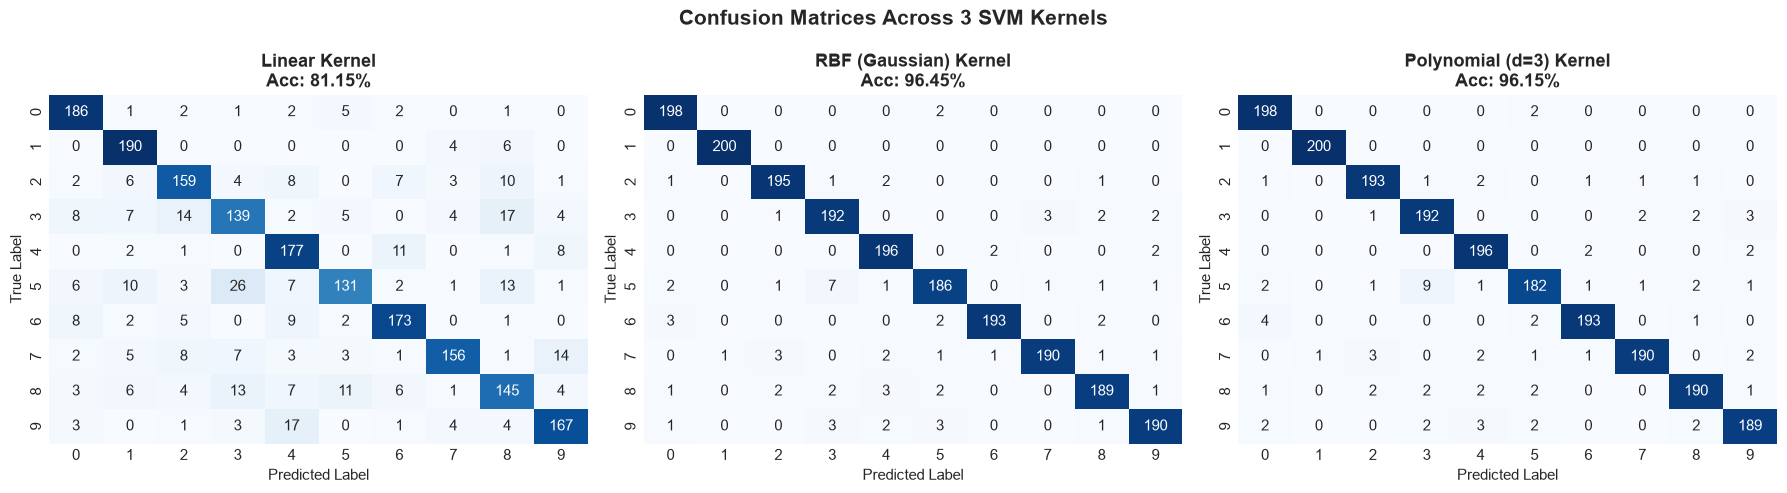

In [9]:
import pandas as pd

summary_data = []
for name, res in results.items():
    summary_data.append({
        "Kernel": name,
        "Accuracy (%)": f"{res['accuracy'] * 100:.2f}%",
        "Macro F1-Score": f"{res['macro_f1']:.4f}",
        "Train Time (s)": f"{res['train_time']:.2f}",
        "Inference Time (s)": f"{res['infer_time']:.2f}",
        "Latency (ms/sample)": f"{res['latency_ms']:.3f}"
    })

summary_df = pd.DataFrame(summary_data)
print("\n--- 3-KERNEL COMPARISON SUMMARY TABLE ---")
print(summary_df.to_string(index=False))
summary_df.to_csv('outputs/kernel_comparison_results.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (name, res) in enumerate(results.items()):
    sns.heatmap(res['confusion_matrix'], annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[i],
                xticklabels=range(10), yticklabels=range(10))
    axes[i].set_title(f"{name} Kernel\nAcc: {res['accuracy']*100:.2f}%", fontsize=13, fontweight='bold')
    axes[i].set_xlabel("Predicted Label", fontsize=11)
    axes[i].set_ylabel("True Label", fontsize=11)

plt.suptitle("Confusion Matrices Across 3 SVM Kernels", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/confusion_matrices.png', dpi=200, bbox_inches='tight')
plt.show()

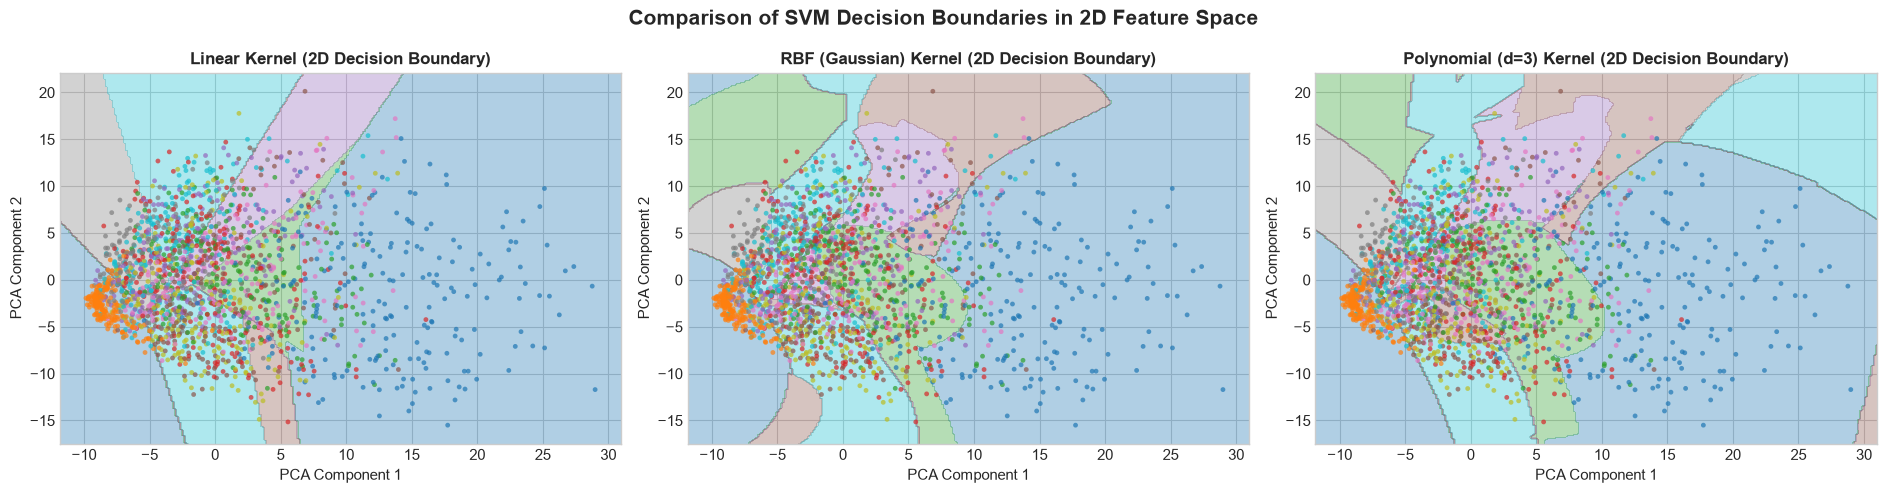

In [10]:
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled[:2000])
y_train_pca = y_train_combined[:2000]

models_2d = {
    "Linear": SVC(kernel='linear', C=1.0).fit(X_train_pca, y_train_pca),
    "RBF (Gaussian)": SVC(kernel='rbf', C=5.0, gamma='scale').fit(X_train_pca, y_train_pca),
    "Polynomial (d=3)": SVC(kernel='poly', degree=3, C=1.0, coef0=1.0).fit(X_train_pca, y_train_pca)
}

x_min, x_max = X_train_pca[:, 0].min() - 2, X_train_pca[:, 0].max() + 2
y_min, y_max = X_train_pca[:, 1].min() - 2, X_train_pca[:, 1].max() + 2
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for i, (name, clf) in enumerate(models_2d.items()):
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    axes[i].contourf(xx, yy, Z, alpha=0.35, cmap='tab10')
    axes[i].scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train_pca, cmap='tab10', s=12, edgecolors='none', alpha=0.7)
    axes[i].set_title(f"{name} Kernel (2D Decision Boundary)", fontsize=12, fontweight='bold')
    axes[i].set_xlabel("PCA Component 1")
    axes[i].set_ylabel("PCA Component 2")

plt.suptitle("Comparison of SVM Decision Boundaries in 2D Feature Space", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/pca_decision_boundaries.png', dpi=200, bbox_inches='tight')
plt.show()

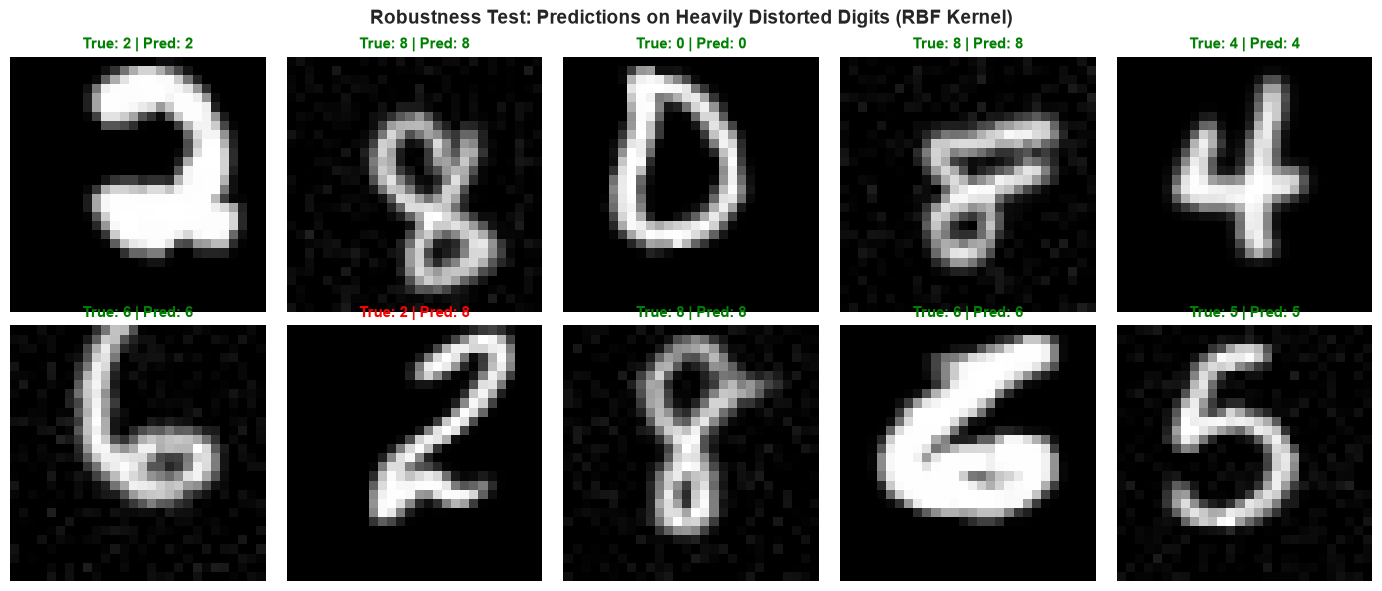

In [11]:
best_model = results['RBF (Gaussian)']['model']

sample_indices = np.random.choice(len(X_test_sub), 10, replace=False)
test_originals = X_test_sub[sample_indices]
true_labels = y_test_sub[sample_indices]

distorted_samples = []
for idx, img in enumerate(test_originals):
    distorted = augment_opencv(img) if idx % 2 == 0 else augment_tensorflow(img)
    distorted_samples.append(distorted)

distorted_samples = np.array(distorted_samples)

distorted_flat = distorted_samples.reshape(len(distorted_samples), -1).astype(np.float32)
distorted_scaled = scaler.transform(distorted_flat)
predictions = best_model.predict(distorted_scaled)

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for i in range(10):
    row, col = divmod(i, 5)
    axes[row, col].imshow(distorted_samples[i], cmap='gray')
    is_correct = (predictions[i] == true_labels[i])
    color = 'green' if is_correct else 'red'
    axes[row, col].set_title(f"True: {true_labels[i]} | Pred: {predictions[i]}", fontsize=11, fontweight='bold', color=color)
    axes[row, col].axis('off')

plt.suptitle("Robustness Test: Predictions on Heavily Distorted Digits (RBF Kernel)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/robustness_test.png', dpi=200, bbox_inches='tight')
plt.show()